In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns


In [2]:

df_raw = pd.read_csv('/Users/fadricampell/Desktop/HSLU/CIP02/CIP/new_structure/outputs/2025-03-28_cleaned_data.csv', dtype={'spec_listing_id': 'object'})

#print(len(df_raw))

# Drop rows with missing price values
df_raw = df_raw.dropna(subset=["spec_price_chf"])

print(df_raw.describe(include='all'))


print(df_raw.dtypes)

print(f'The raw dataset after scraping and pre-cleaning has {len(df_raw)} boats listings')

print(df_raw['spec_condition'].value_counts())

                                                      URL  spec_price_chf  \
count                                                2329    2.329000e+03   
unique                                               2329             NaN   
top     https://www.boot24.ch/chde/motorboote/idea-mar...             NaN   
freq                                                    1             NaN   
mean                                                  NaN    8.474461e+04   
std                                                   NaN    1.182711e+05   
min                                                   NaN    5.000000e+02   
25%                                                   NaN    1.990000e+04   
50%                                                   NaN    4.400000e+04   
75%                                                   NaN    9.800000e+04   
max                                                   NaN    1.228340e+06   

       spec_listing_id  attributes_counter      spec_condition  \
count    

## Data cleaning & Feature engineering
Altough the data has been pre-cleaned after the web-scraping process, we still need to make some adjustments before we can fit a model.

Steps:
- Remove rows with missing price
- Analyze columns for missing values

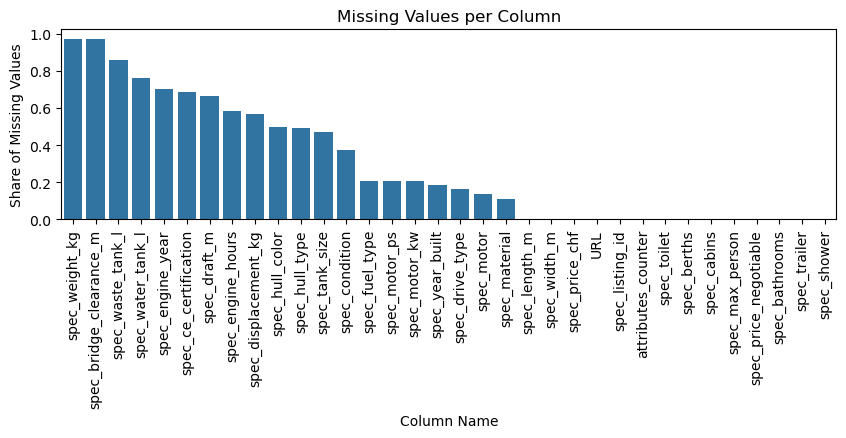

In [3]:
# See which columns have a lot of NA's and are not suitable as predictors
# Count missing values for each column
missing_counts = df_raw.isna().sum()

# Sort by number of missing values and calculate share from whole df
missing_counts = missing_counts.sort_values(ascending=False)
missing_share = missing_counts / len(df_raw)

# Plot counts of missing values per column
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_share.index, y=missing_share.values)
plt.xticks(rotation=90)
plt.ylabel("Share of Missing Values")
plt.xlabel("Column Name")
plt.title("Missing Values per Column")
plt.subplots_adjust(bottom=0.5)
plt.show()


There are many variables that have way to many missing values and we would need to drop a lot of lisings if we were to include these as predictors in a linear model. We could only use the variables which have very few missing values and have a big dataset to fit Models, but as we're dealing with motorboats it would make no sense to not include specifications on the motor, which intuitively would store a lot of information on the price of a motorboat. So we decide to keep all columns with less than 40% missing values , this would make the cut at 'spec_condition' as the condition as well as motor specifications make a lot of sense to include in a hedonic model for motorboats. 

Therefore we will first drop all columns that contain 40% and more missing values and then remove all listings which contain missing values in the remaining columns. This will cost us many observations but leave us with a clean Dataset to fit linear models. Imputing missing values with means or common values would bias our model, which we don't want.

In [4]:
# Exclude all columns with values shares bigger than 0.3
new_cols = missing_share[missing_share<=0.4].keys()
#print(new_cols)

# # subset df to only these columns and for the others drop all
df_new = df_raw[new_cols].dropna()

print(f'The clean dataset ready for model fitting has {len(df_new)} boat listings.')



The clean dataset ready for model fitting has 1036 boat listings.


In the next steps we will have a closer look at all the variables in the dataframe. First we check the distribution of the outcome variable 'spec_price_chf' which should be gaussian distributed in order to meet the assumptions for linear models we will use later. But because we're dealing with prices, we actually expect a right skewed normal distribution which we can then make more symetric by applying a log-transformation. In a second step we will have a closer look at all the predictors and see if we need to summarize some categories for the categorical varibles or even need to celan some listings, because some values might be unrealistic. 

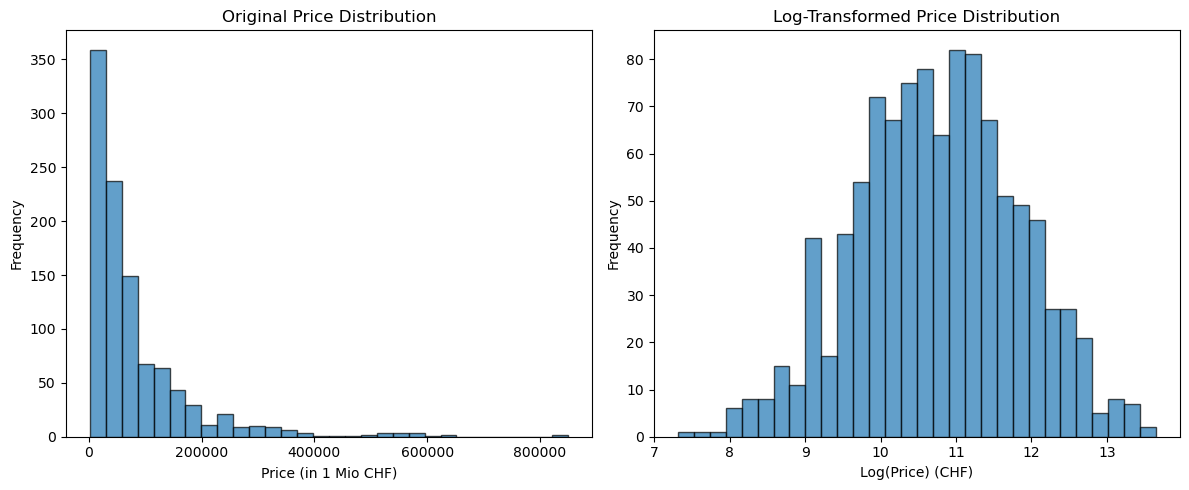

Index(['spec_condition', 'spec_fuel_type', 'spec_motor_ps', 'spec_motor_kw',
       'spec_year_built', 'spec_drive_type', 'spec_motor', 'spec_material',
       'spec_length_m', 'spec_width_m', 'spec_price_chf', 'URL',
       'spec_listing_id', 'attributes_counter', 'spec_toilet', 'spec_berths',
       'spec_cabins', 'spec_max_person', 'spec_price_negotiable',
       'spec_bathrooms', 'spec_trailer', 'spec_shower', 'log_spec_price_chf'],
      dtype='object')


In [5]:
# Apply log transformation
df_new["log_spec_price_chf"] = np.log(df_new["spec_price_chf"])

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original price distribution
axes[0].hist(df_new["spec_price_chf"], bins=30, edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Price (in 1 Mio CHF)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Original Price Distribution")

# Log-transformed price distribution
axes[1].hist(df_new["log_spec_price_chf"], bins=30, edgecolor="black", alpha=0.7)
axes[1].set_xlabel("Log(Price) (CHF)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Log-Transformed Price Distribution")

# Adjust layout
plt.tight_layout()
plt.show()

print(df_new.columns)

We see that the log-transformation of the outcome variable is necessary to be able to fit an Orindary Least Square model (OLS). Now we wil look at all the predictors seperately and will see if we need some further feature engineering or data cleaning


            spec_condition spec_fuel_type  spec_motor_ps  spec_motor_kw  \
count                 1036           1036    1036.000000    1036.000000   
unique                   8             15            NaN            NaN   
top     sehr guter Zustand       Bleifrei            NaN            NaN   
freq                   470            878            NaN            NaN   
mean                   NaN            NaN     224.068533     164.777413   
std                    NaN            NaN     115.734135      85.095366   
min                    NaN            NaN       1.000000       0.700000   
25%                    NaN            NaN     135.000000      99.000000   
50%                    NaN            NaN     238.500000     175.500000   
75%                    NaN            NaN     300.250000     221.000000   
max                    NaN            NaN     700.000000     515.000000   

        spec_year_built spec_drive_type   spec_motor   spec_material  \
count       1036.000000    

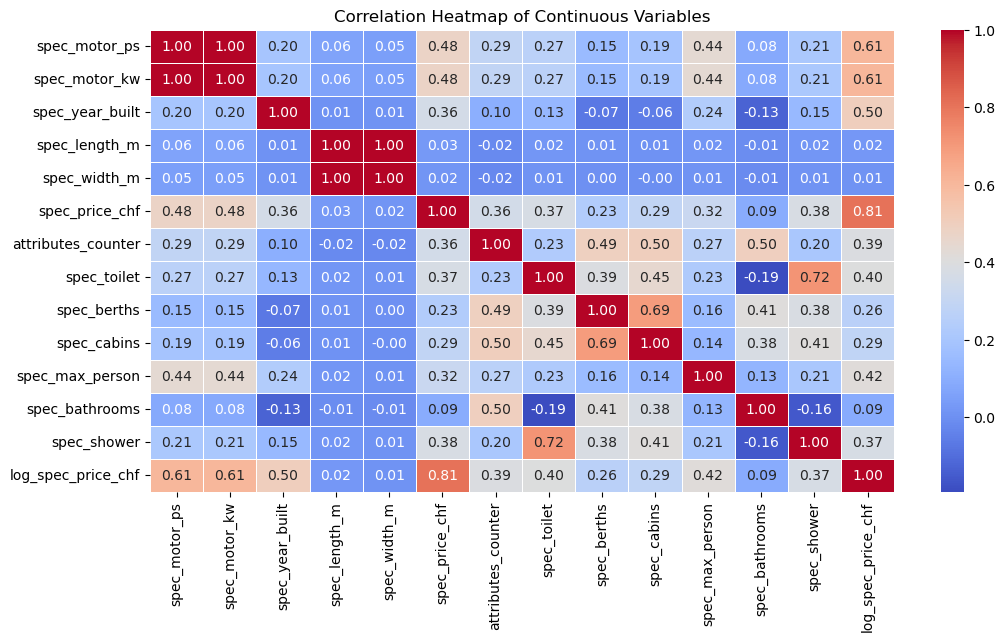

In [6]:
# Check summary for every predictor
print(df_new.describe(include='all'))

# Select only continuous variables
num_cols = df_new.select_dtypes(include=['float64', 'int64']).columns

# Compute correlation matrix
plt.figure(figsize=(12, 6))
sns.heatmap(df_new[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Continuous Variables")
plt.show()



From the first summary we conclude:
- 'spec_fuel_type' needs to be further investigated to maybe summarize the categories as 15 are probably to many
- 'spec_motor' needs to be summarized (eg. summarize to constructor name), as we have over 600 differnt motors and this will certainly lead to overfitting, as to many degrees of freedom will be used on the fitting of motor and not the residuals
- some very high vlaues in width and length need to be checked further and maybe cleaned

From the correlation chart we can see that some predictors are highly correlated with others. When fitting linear models we want to avoid having colinearity in our predictors as this confuses the model. Based on this correlation chart we decide:
- drop 'spec_motor_kw' as this is just another unit to explain the motor's power and we use now only 'spec_motor_ps' as predictor as this unit is more intuitive
- introduce column for area, which condenses information of the two columns 'spec_length_m' and 'spec_width_m'
- variables like 'spec_toilets' and 'spec_bathrooms' also correlate highly, but we will keep it for now, as we are not expecting these to be very impactful predictors and they could still help to make fine-grained predictions. We will later see and simplify models also by removing these kind of variables.

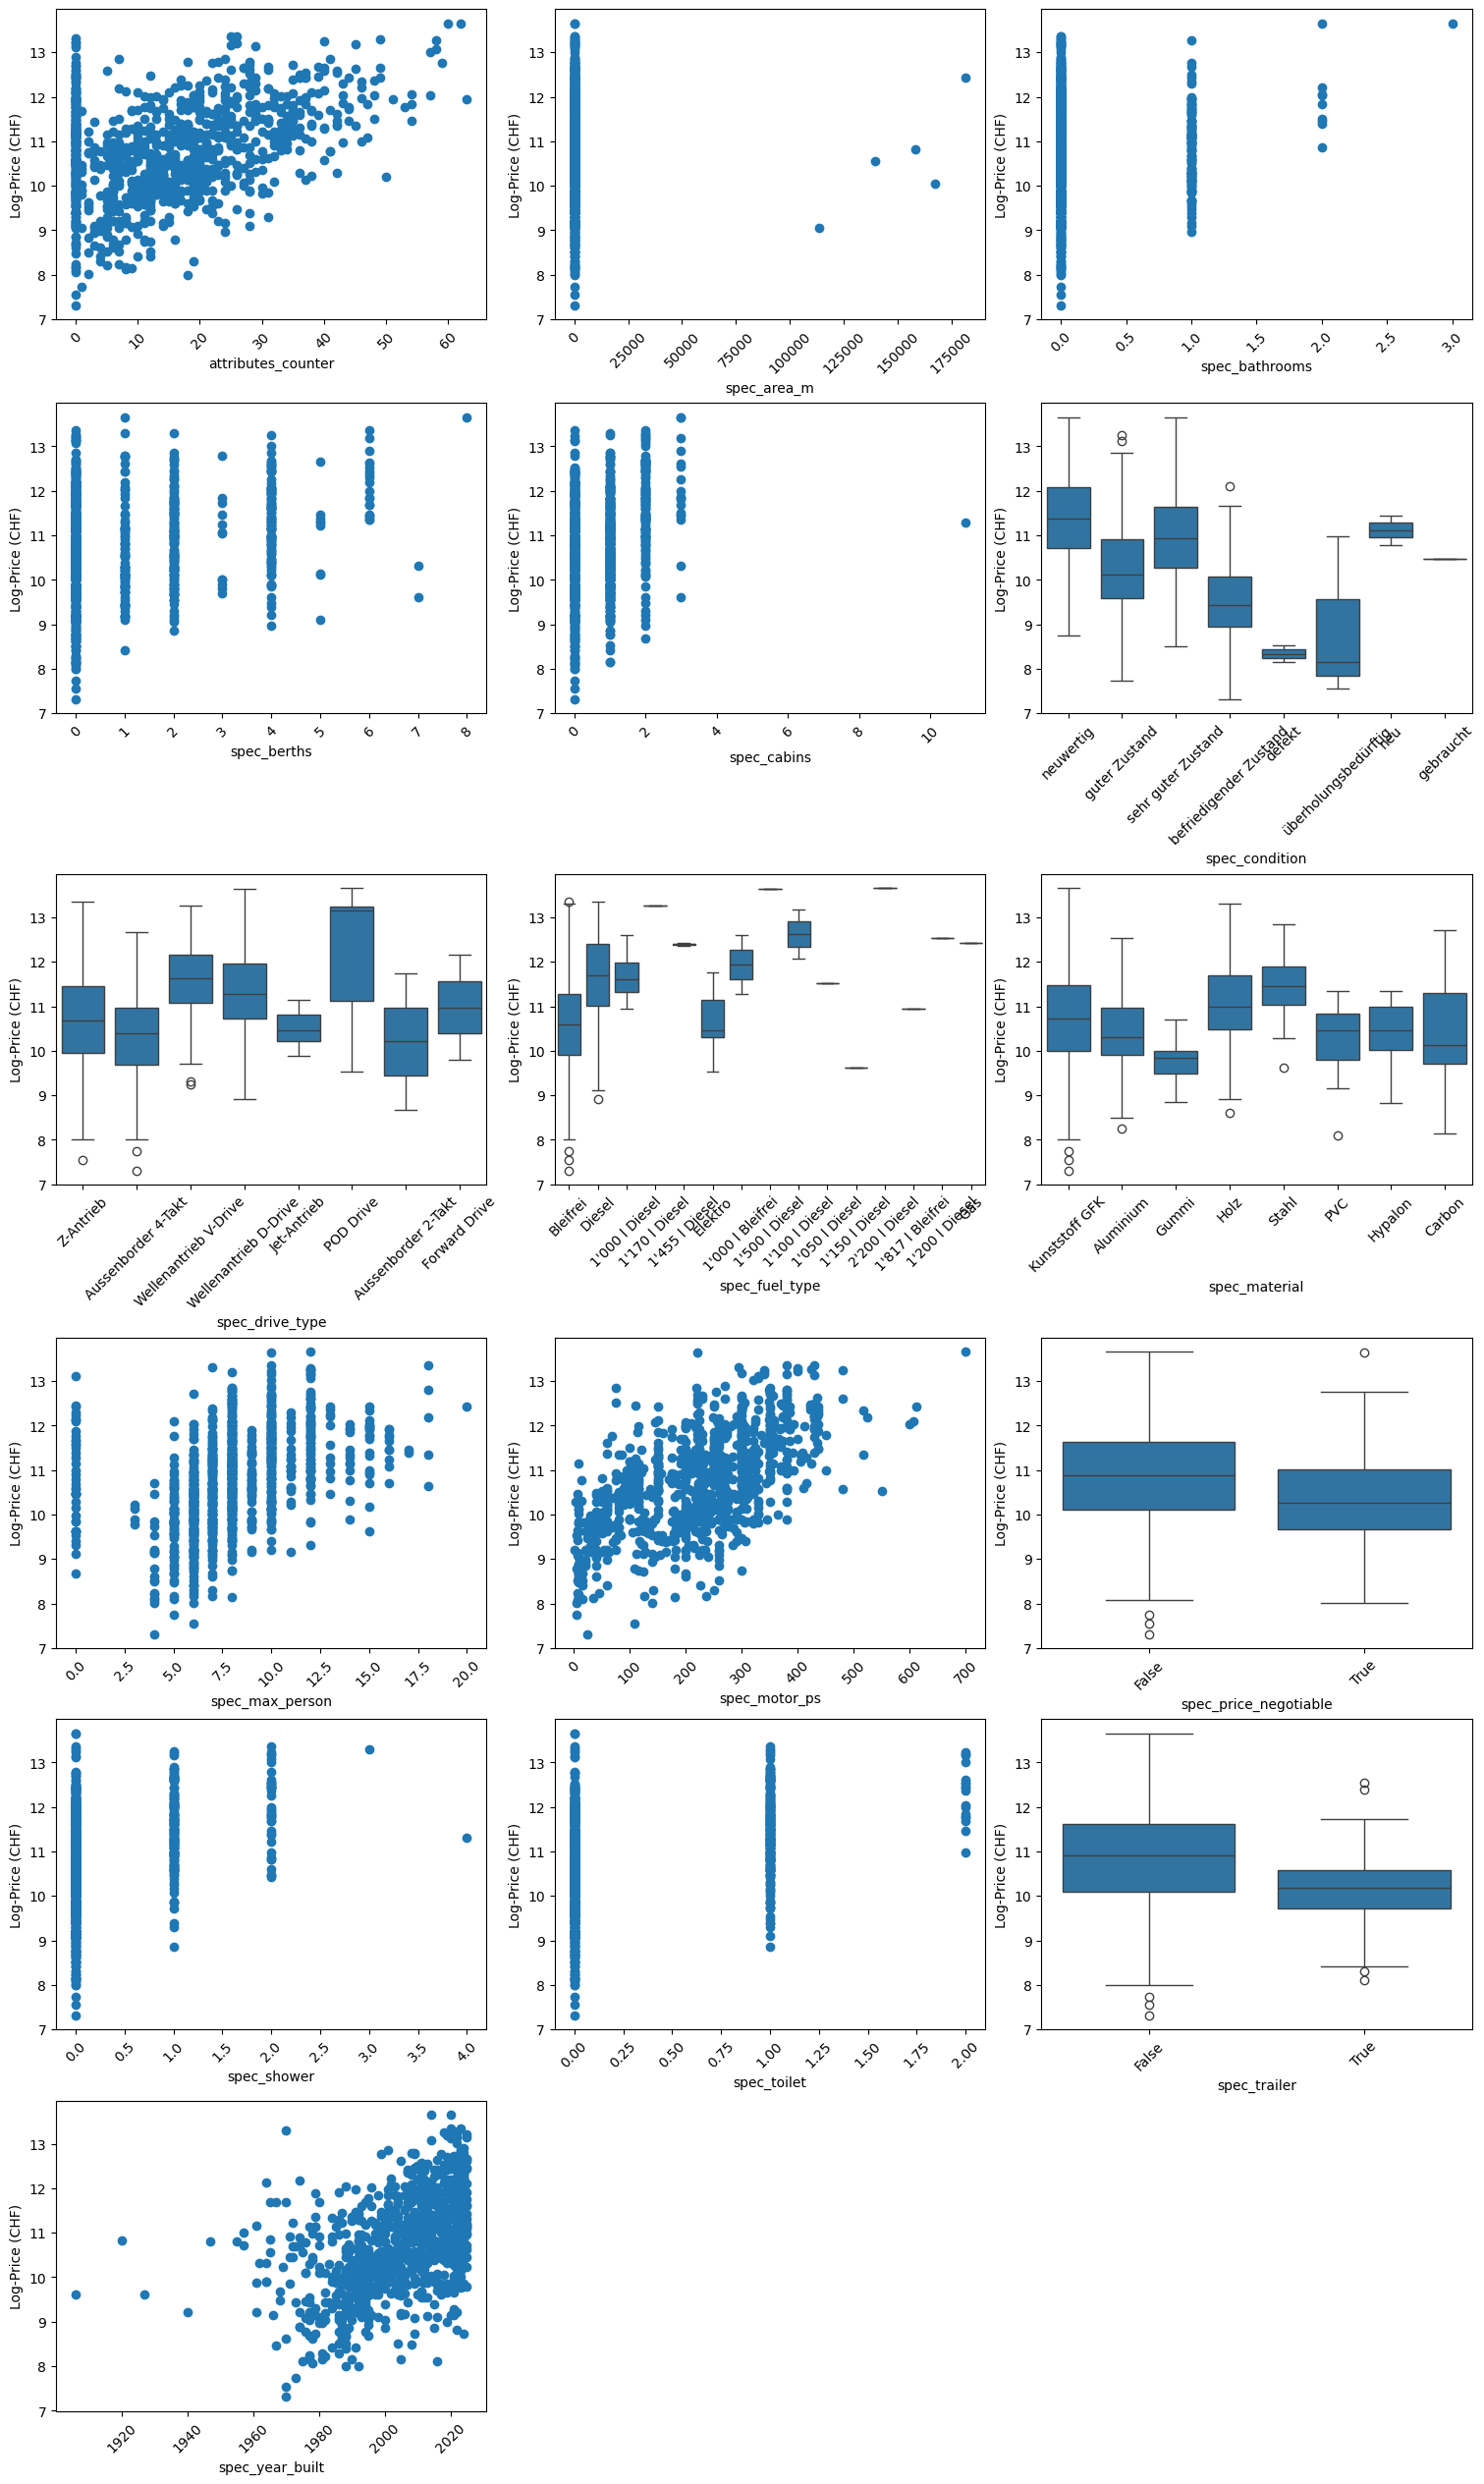

spec_motor
Volvo Penta            74
Yamaha                 59
Mercruiser             52
Mercury                42
Honda                  22
Suzuki                 15
Volvo                   9
Volvo Penta 4.3 GXI     8
Indmar                  6
OMC                     5
Name: count, dtype: int64
There are 667 unique motor types


In [7]:
# create new variable area
df_area = df_new.drop(columns=['spec_motor_kw'])
df_area.loc[:,'spec_area_m'] = df_area['spec_width_m'] * df_area['spec_length_m']

# Select categorical variables (excluding ID and URL)
cat_cols = df_area.select_dtypes(include=['string', 'object', 'bool']).columns.difference(['spec_listing_id', 'URL'])

# Set up the plot grid
n_plots = len(cat_cols) + len(num_cols)
fig, axes = plt.subplots(nrows=(n_plots // 3) + 1, ncols=3, figsize=(15, n_plots * 1.5), constrained_layout=True)

# Flatten axes array for easier iteration
axes = axes.flatten()

# Create boxplots for each categorical variable
for i, col in enumerate(df_area.columns.difference(['spec_listing_id', 'URL', 'spec_motor', 'spec_price_chf', 'log_spec_price_chf', 'spec_length_m', 'spec_width_m'])):

    if df_area[col].dtype in ['string', 'object', 'bool']:
        sns.boxplot(data=df_area, x=col, y="log_spec_price_chf", ax=axes[i])
    elif df_area[col].dtype in ['int64', 'float64']:
        axes[i].scatter(df_area[col], df_area["log_spec_price_chf"])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Log-Price (CHF)")
    axes[i].tick_params(axis='x', rotation=45)
        

# Remove unused subplots (if any)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.plot()
plt.show()

# Check amount of motor types
motor_types = df_area['spec_motor'].value_counts()
print(motor_types.head(10)) # show top 10 motor types
print(f'There are {len(motor_types)} unique motor types')


From the plots we make the following decisions:
- Summarize all Diesel and Bleifrei fuel types in 'spec_fuel_type' to increase group sizes
- Summarize motors to only the most common motor constructors, to decrease groups and increase group sizes
- Remove outliers that are detected in the variable area, we drop all boats listings with boats wider than 100m (which seems unrealistic) 

motor_constructor
Volvo Penta    298
Mercruiser     209
other          180
Yamaha         100
Mercury         93
Honda           46
Volvo           34
Suzuki          31
Indmar          27
OMC             13
Name: count, dtype: int64


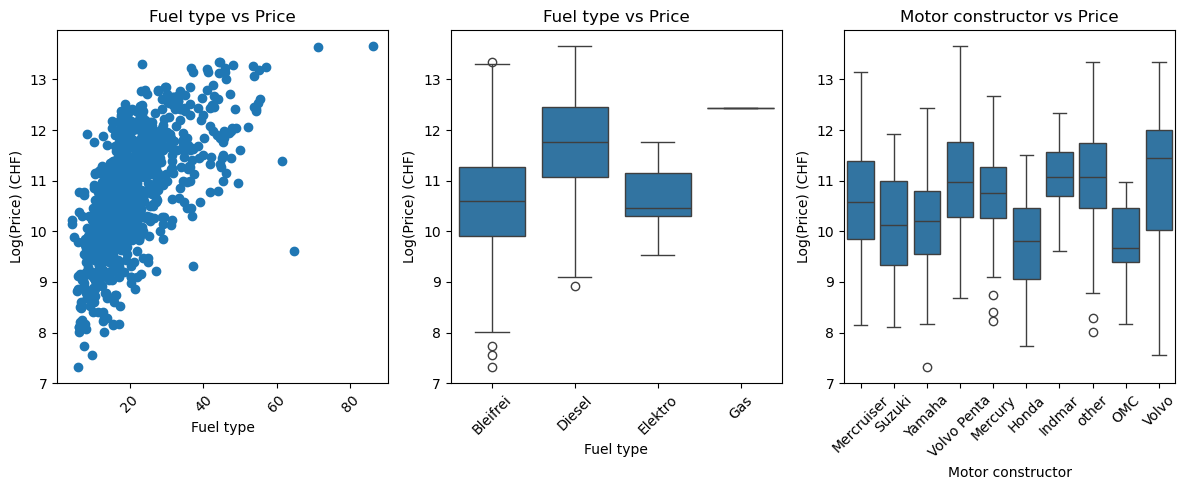

In [8]:
# Exclude outliers in size
df_clean = df_area[df_area['spec_width_m'] < 100].copy()

# Summarize fuel types to only standard 'Bleifrei', 'Diesel' etc.
df_clean.loc[:,'spec_fuel_type'] = df_clean['spec_fuel_type'].replace(
    to_replace={r".*Bleifrei.*": "Bleifrei", r".*Diesel.*": "Diesel"},
    regex=True
)

# Introduce variable with motor constructor to replace 'spec_motor'
# Define names of  most common constructors that occur in dataset
constructors = ['Volvo Penta', 'Yamaha', 'Mercruiser', 'Mercury', 'Suzuki', 'Honda', 'Volvo', 'Indmar', 'OMC']

# Function to extract constructor name from full motor string
def extract_constructor(motor):
    if pd.isna(motor):
        return "other"
    for brand in constructors:
        #if motor.startswith(brand):
        if brand in motor or brand.upper() in motor or brand.lower() in motor:
            return brand
    return "other"

# set motor constructor
df_clean.loc[:,'motor_constructor'] = df_clean['spec_motor'].apply(extract_constructor)
print(df_clean['motor_constructor'].value_counts())

# Visualize manipulations
# Create Plot layout
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# Plot 1: Area vs. Price to show new dataset without outliers
axes[0].scatter(x=df_clean['spec_area_m'], y=df_clean['log_spec_price_chf'])
axes[0].set_xlabel("Fuel type")
axes[0].set_ylabel("Log(Price) (CHF)")
axes[0].set_title("Fuel type vs Price")
axes[0].tick_params(axis='x', rotation=45)

# Plot 1: Fuel type vs. Price to show new standardized fuel types
sns.boxplot(data=df_clean, x='spec_fuel_type', y="log_spec_price_chf", ax=axes[1])
axes[1].set_xlabel("Fuel type")
axes[1].set_ylabel("Log(Price) (CHF)")
axes[1].set_title("Fuel type vs Price")
axes[1].tick_params(axis='x', rotation=45)

# Plot 4: Motor constructor vs. Price to show motors summarized by constructor
sns.boxplot(data=df_clean, x='motor_constructor', y="log_spec_price_chf", ax=axes[2])
axes[2].set_xlabel("Motor constructor")
axes[2].set_ylabel("Log(Price) (CHF)")
axes[2].set_title("Motor constructor vs Price")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Plot 1:** New variable 'area' shows linear relationship with log-price. Which means the price of a boat grows with it's size exponentially. \
**Plot 2:** Average prices for boats with different fuel types seem to differ. \
**Plot 3:** Using the motor constructor as new variable makes sense, the category that summarizes all motor models from other not so common manufacturers shows similar variance in price as others, which allows us to summarize.

## Analysis of Pricing - OLS
In this section we want to see what factors have the greatest impact on the pricing of motorboats. From the visual analyisis above we could aready see that almost all variables have some effect on the pricing the most obvious relationships showed the variables: area, motor ps and the self-correlating specifications like (cabins, berths, bathrooms, showers, toilets). We also see differing prices in drive type and fuel types. In this step we want to see the general size of effect that a variable has on motor boat pricing. We use the statsmodels library to fit a simple Ordinary Least Square model (OLS), to analyze the data. This library brings easy interpretable model summaries. In further steps when we try to build a model that predicts very well, we move to a more advance library for predicitve modelling as this gives us more functionality to perform cross validations etc.

In [16]:
from patsy import dmatrices
import statsmodels.api as sm

# Define variables to exclude
exclude_cols = ['URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf', 'log_spec_price_chf', 'spec_motor', 'spec_motor_kw', 'spec_cabin', 'spec_berth']

# Construct the formula correctly
predictors = ' + '.join(df_clean.columns.difference(exclude_cols))
formula = f'log_spec_price_chf ~ {predictors}'

print(f"Formula used: \n{formula}")

# Use dmatrices to form regression equation, the function creates the necessary matrices
y, X = dmatrices(formula, data=df_clean, return_type='dataframe')

# print(y[:3])
# print(X[:3])

mod = sm.OLS(y, X)
res = mod.fit()
print(res.summary())


print(df_clean[df_clean['spec_condition']=='gebraucht']['spec_price_chf'])

Formula used: 
log_spec_price_chf ~ attributes_counter + motor_constructor + spec_area_m + spec_bathrooms + spec_berths + spec_cabins + spec_condition + spec_drive_type + spec_fuel_type + spec_material + spec_max_person + spec_motor_ps + spec_price_negotiable + spec_shower + spec_toilet + spec_trailer + spec_year_built
                            OLS Regression Results                            
Dep. Variable:     log_spec_price_chf   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.840
Method:                 Least Squares   F-statistic:                     121.4
Date:                Mon, 07 Apr 2025   Prob (F-statistic):               0.00
Time:                        09:11:59   Log-Likelihood:                -568.81
No. Observations:                1031   AIC:                             1230.
Df Residuals:                     985   BIC:                             1457.
Df Model:                          45          

Interpretation of the Model Summary:
- Statistically speaking the different motor cobstructors don't have a significant effect on the price, altough the effect size is still notable for some motor constructors. We keep this variable in the model for now, as it can still help make better predictions. We can also further investigate if there is an interaction between motor constructor and motor_ps.
- As expected the condition of the boat has a big impact on the pricing: Newer have higher prices than boats in bad condition.
- The different drive types also don't seem to have a statistically significant effect on pricing, but we keep them for our predictive modelling approach
- Boats with Diesel fuels and electric motors are significantly more expensive than boats with 'Bleifrei' fuel. Eletric motor boats are at average the most expensive type
- The material of the boat aswell has a significant impact on pricing, wooden motorboats are at average the most expensive
- Surprisingly, the negotiability of the price has an impact on pricing itself. If the price is negotiable it is at average lower. This makes sense if we think for newer boats that are in good condition, the price is rather set and wont be negotiated, as boats in bad condition would have more discrepancy in pricing. We should check for correlations between these predictors.
- Number of attributes significantly increases the price of a boat
- The price of a boat significantly increases with it's size (area)
- Surprisingly, the boat price decreases with the number of bathrooms, maybe because more than 1 bathrooms are redundant? This variable also correlates with number of shower and toilets, maybe removing some predictors could lead to different outcomes
- Same issue with berths and cabins which correlate highly so the model cant distinguish the effects, making them both insignificant
- The boat price increases significantly with it's motor ps
- Newer boats (more recent construction) are more expensive than older boats


In a next step we would like to see if we can simplify the model even more, we drop correlating variable such as cabins~berths, bathrooms~showers~toilets and check what implications this has on the models ability to explain variance (does R-Squared change?)

In [17]:
# Define variables to exclude
exclude_cols = ['URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf', 'log_spec_price_chf', 
                'spec_motor','spec_cabins', 'spec_shower', 'spec_toilet', 'spec_max_person', 'spec_negotiable', 'spec_bathroom']

# Define
predictors = ' + '.join(df_clean.columns.difference(exclude_cols))
formula = f'log_spec_price_chf ~ {predictors}'

print(f"Formula used: \n{formula}")

# # Convert all string[python] columns to object
# df = df_clean.astype({col: "object" for col in df_clean.select_dtypes(include="string").columns})

# Use dmatrices to form regression equation, the function creates the necessary matrices
y, X = dmatrices(formula, data=df_clean, return_type='dataframe')

# print(y[:3])
# print(X[:3])

mod = sm.OLS(y, X)
res = mod.fit()
print(res.summary())

Formula used: 
log_spec_price_chf ~ attributes_counter + motor_constructor + spec_area_m + spec_bathrooms + spec_berths + spec_condition + spec_drive_type + spec_fuel_type + spec_material + spec_motor_ps + spec_price_negotiable + spec_trailer + spec_year_built
                            OLS Regression Results                            
Dep. Variable:     log_spec_price_chf   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.840
Method:                 Least Squares   F-statistic:                     133.0
Date:                Mon, 07 Apr 2025   Prob (F-statistic):               0.00
Time:                        10:00:22   Log-Likelihood:                -571.25
No. Observations:                1031   AIC:                             1227.
Df Residuals:                     989   BIC:                             1434.
Df Model:                          41                                         
Covariance Type:            

From the summary we can see that even after dropping some variables, the model can explain the same amount of variance from the data as before, as the adjusted R-Squared remained the same (0.84). This model is way more suitable for practical implications, as the goal in the end is to predict prices of a boat with limited information. So it makes sense to only focus on the predictors that really have an impact on prediction quality. This we will inspect in the next section where we will perform cross-validations for different types of linear models. But before we do this, we want to check if a motor constructor and motor ps interaction would make sense. We would expect that the price of the motor rises differently with motor power for different constructors.

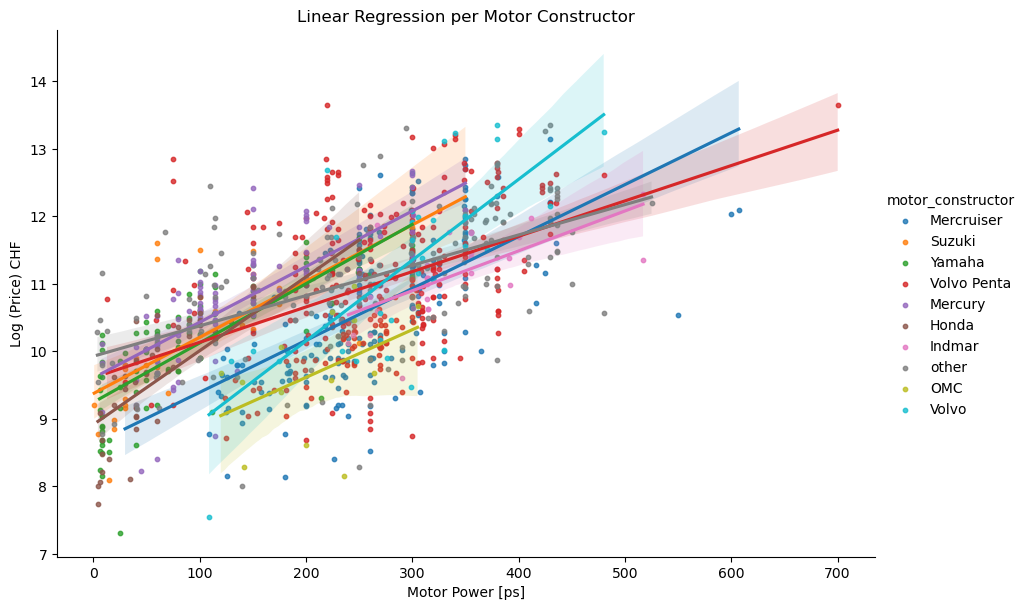

In [23]:
# Plot linear models per constructor
sns.lmplot(data=df_clean,
           x='spec_motor_ps',
           y='log_spec_price_chf',
           hue='motor_constructor',
           aspect=1.5,
           height=6,
           scatter_kws={'s': 10}, # point size
           markers='o')

plt.title("Linear Regression per Motor Constructor")
plt.xlabel("Motor Power [ps]")
plt.ylabel("Log (Price) CHF")
plt.show()


Looking at the interaction plot for Motor Power and motor constructor, we can already see by eye, that there is no significant interaction. The Regression lines for each motor constructor seem to have about the same slope, so including an interaction term in our model would loose us some degrees of freedom.

## Hedonic Model and Predicions

We start making predictions using the sklearn library, where we can also easily perform cross-validations. We switch library as we want to use the convenient functions regarding cross validation and test/train data splitting. In this stage we don't care so much about the summary (sklear doesnt include model summaries for OLS). 

In the section before we saw that the variables with the biggest impact on pricing of motor boats are: construction year, motor power, boat size, number of additional equipment (attributes_counter), condition, material and the fuel type of the motor. These variables have a significant effect on the pricing, so we will certainly include these in our model As our goal is to make a good predictive model, we don't care so much about significance of effects (P-values) and more about if a predictor actually increases the overall prediction accuracy. So in this section we will try many differnt model and check their performance with cross-validation.

We do cross-validation runs first only for the model with the defined core-variables and then add a new variable to this model for every run. As the linear model is additive with the effects we can chcek for each variable, if it enhances the predictive power of the model. We then add all variables that increase the prediction accuracy. In the end we should have the best possible model (in boundaries of OLS).

To evaluate the predictive performance of our core model and assess the value of adding individual predictors, we perform stratified 20-fold cross-validation. The outcome variable (log_spec_price_chf) is binned into quantiles to ensure that each fold has a similar price distribution in both train and test splits. For each additional predictor, we run the same cross-validation and compare the resulting RMSEs across models.

To visualize the results, we use a boxplot that shows the distribution of RMSE scores for each model across the 20 folds. The baseline (core model) serves as a reference point, helping us see which predictors improve or worsen model performance. We also include KDE plots of train and test data for each fold to confirm that the stratified splits preserve the target distribution.

/var/folders/dz/xk92rf811x11gfspml0l9cdr0000gn/T/ipykernel_1606/496520735.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(labels,rotation=45, ha='right', rotation_mode='anchor')


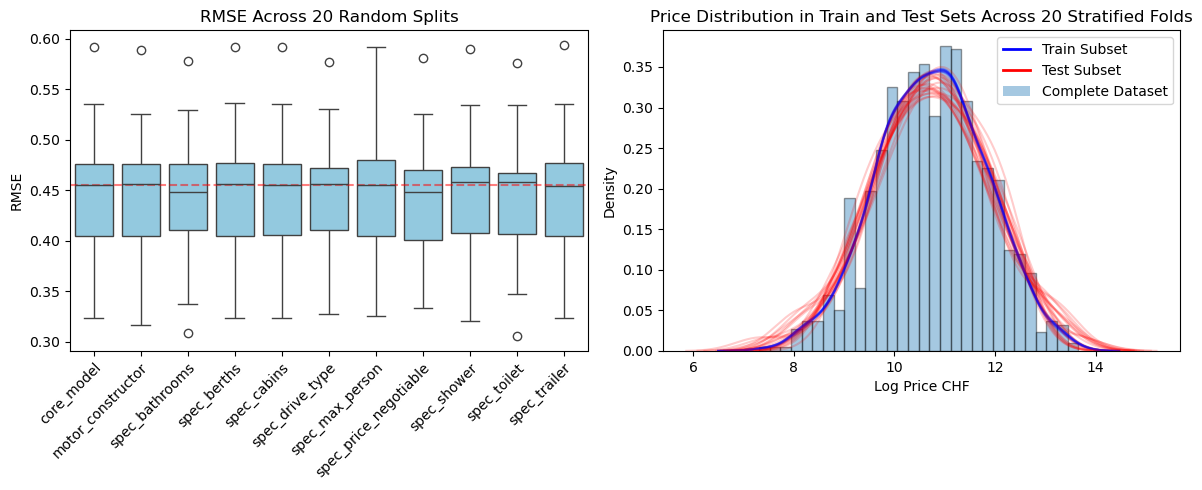

In [103]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# Number of cross validation folds per model (how many times we perform cv on model)
n_folds = 20

# Define the columns we want in every model
core_columns = ['spec_condition', 'spec_fuel_type', 'spec_motor_ps', 'spec_year_built', 'spec_material', 'spec_area_m', 'attributes_counter']

# Define additional predictors that are to be added one by one
additional_predictors = df_clean.columns.difference([*core_columns,'URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf', 'log_spec_price_chf', 'spec_motor', 'spec_motor_kw'])

# One-hot encode dummy variables and setup X for core model
X_core = df_clean[core_columns]
X_core = pd.get_dummies(X_core, columns=X_core.select_dtypes(include="object").columns, drop_first=True)

# Bin price into 10 quantiles to make statified splitting of test and train datasets possible
y_log_price = df_clean['log_spec_price_chf']
y_bins = pd.qcut(y_log_price, q=10, labels=False)  # 10 quantile bins

# We split the data in test and training data for each fold of cross-validation
# The splitting is stratified for the outcome log_price which is split into 10 quantile bins
# For each fold of cross-validation a training and test dataset is created, with the same price distribution
# This also allows us to use the same dataset partitioning for the cv of each model, so we can nicely compare these
skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=420)

# Run cross-validation for core model
cv_core = cross_val_score(
    estimator=LinearRegression(),
    X=X_core,
    y=y_log_price,
    scoring='neg_root_mean_squared_error',
    cv=skf.split(X_core, y_bins)  # stratify using binned y
)

# Create dataframe to save cross validation results
df_cross_validation = pd.DataFrame()
df_cross_validation['core_model'] = -cv_core

# Run cross-validation for core model +1 additional predictor for each predictor
for pred in additional_predictors:
    X_pred = df_clean[core_columns + [pred]]
    X_pred = pd.get_dummies(X_pred, columns=X_pred.select_dtypes(include="object").columns, drop_first=True) # encode dummy variables
    
    cv_pred = cross_val_score(
        estimator=LinearRegression(),
        X=X_pred,
        y=y_log_price,
        scoring='neg_root_mean_squared_error',
        cv=skf.split(X_core, y_bins)
    )

    # add this to df
    df_cross_validation[pred] = -cv_pred

#print(df_cross_validation)

# Visualize differences of models with boxplot, the core model serves as baseline
# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot of RMSE
sns.boxplot(data=df_cross_validation, color="skyblue", ax=axes[0])
axes[0].axhline(y=np.median(df_cross_validation['core_model']), ls='--', c='red', alpha=0.5) # add median RMSE of core model as baseline
labels = axes[0].get_xticklabels()
axes[0].set_xticklabels(labels,rotation=45, ha='right', rotation_mode='anchor')
#axes[0].tick_params(axis='x', rotation=45, ha='right', rotation_mode='anchor')
axes[0].set_title(f"RMSE Across {n_folds} Random Splits")
axes[0].set_ylabel("RMSE")


# To make sure the stratified dataset splitting worked we want to have a look at the price distributions within those datasets
## Loop through folds and visualize distribution of price from train and test datasets
plt.hist(df_clean["log_spec_price_chf"], bins=30, edgecolor="black", alpha=0.4, density=True, label='Overall Histogram') # distribution of whole dataset in the background
for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X_core, y_bins)):
    y_train = y_log_price.iloc[train_idx]
    y_test = y_log_price.iloc[test_idx]
    
    sns.kdeplot(y_train, color='blue', alpha=0.1)
    sns.kdeplot(y_test, color='red', alpha=0.2)

plt.title(f"Price Distribution in Train and Test Sets Across {n_folds} Stratified Folds")
plt.xlabel('Log Price CHF')
# Add invisible to make a legend
blue_patch = plt.Line2D([0], [0], color='blue', lw=2, label='Train Subset')
red_patch = plt.Line2D([0], [0], color='red', lw=2, label='Test Subset')
plt.legend(handles=[blue_patch, red_patch, 
                    plt.Rectangle((0,0),1,1, alpha=0.4, label="Complete Dataset")])

#plt.grid(True)
plt.tight_layout()
plt.show()



We see that addition of the predictors spec_bathrooms and spec_price_negotiable can add to the models accuracy and therefore will add them to the model. We want to see the difference in performance to the core model when adding these two variables using the same amount of folds and stratified dataset splits.

/var/folders/dz/xk92rf811x11gfspml0l9cdr0000gn/T/ipykernel_1606/665088108.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(labels,rotation=45, ha='right', rotation_mode='anchor')


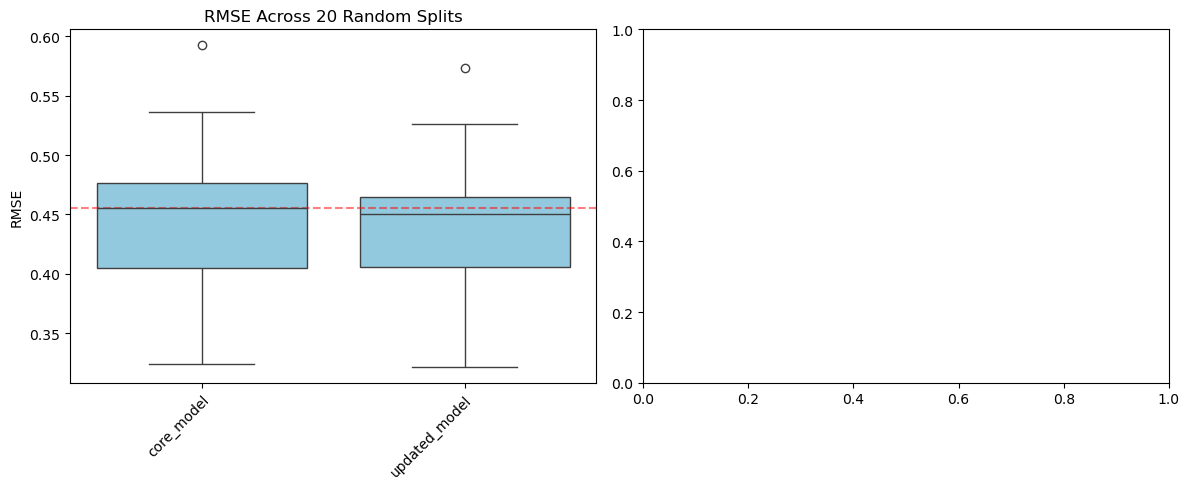

In [110]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# Number of cross validation folds per model (how many times we perform cv on model)
n_folds = 20

# Define the columns we want in every model
core_columns = ['spec_condition', 'spec_fuel_type', 'spec_motor_ps', 'spec_year_built', 'spec_material', 'spec_area_m', 'attributes_counter']

# One-hot encode dummy variables and setup X for core model
X_core = df_clean[core_columns]
X_core = pd.get_dummies(X_core, columns=X_core.select_dtypes(include="object").columns, drop_first=True)

# Bin price into 10 quantiles to make statified splitting of test and train datasets possible
y_log_price = df_clean['log_spec_price_chf']
y_bins = pd.qcut(y_log_price, q=10, labels=False)  # 10 quantile bins

skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=420)

# Run cross-validation for core model
cv_core = cross_val_score(
    estimator=LinearRegression(),
    X=X_core,
    y=y_log_price,
    scoring='neg_root_mean_squared_error',
    cv=skf.split(X_core, y_bins)  # stratify using binned y
)

# Create dataframe to save cross validation results
df_updated = pd.DataFrame()
df_updated['core_model'] = -cv_core

# Run cross-validation for core model +1 additional predictor for each predictor

X_updated = df_clean[core_columns + ['spec_bathrooms', 'spec_price_negotiable']]
X_updated = pd.get_dummies(X_updated, columns=X_updated.select_dtypes(include="object").columns, drop_first=True) # encode dummy variables
    
cv_updated = cross_val_score(
    estimator=LinearRegression(),
    X=X_updated,
    y=y_log_price,
    scoring='neg_root_mean_squared_error',
    cv=skf.split(X_core, y_bins)
    )

# add this to df
df_updated['updated_model'] = -cv_updated

#print(df_cross_validation)

# Visualize differences of models with boxplot, the core model serves as baseline
# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot of RMSE
sns.boxplot(data=df_updated, color="skyblue", ax=axes[0])
axes[0].axhline(y=np.median(df_updated['core_model']), ls='--', c='red', alpha=0.5) # add median RMSE of core model as baseline
labels = axes[0].get_xticklabels()
axes[0].set_xticklabels(labels,rotation=45, ha='right', rotation_mode='anchor')
#axes[0].tick_params(axis='x', rotation=45, ha='right', rotation_mode='anchor')
axes[0].set_title(f"RMSE Across {n_folds} Random Splits")
axes[0].set_ylabel("RMSE")


#plt.grid(True)
plt.tight_layout()
plt.show()

Index(['spec_condition', 'spec_fuel_type', 'spec_motor_ps', 'spec_year_built',
       'spec_drive_type', 'spec_motor', 'spec_material', 'spec_length_m',
       'spec_width_m', 'spec_price_chf', 'URL', 'spec_listing_id',
       'attributes_counter', 'spec_toilet', 'spec_berths', 'spec_cabins',
       'spec_max_person', 'spec_price_negotiable', 'spec_bathrooms',
       'spec_trailer', 'spec_shower', 'log_spec_price_chf', 'spec_area_m',
       'motor_constructor'],
      dtype='object')
1031
1031
3         11
4        371
5       1009
6         36
9        384
        ... 
2313     693
2316     873
2319     144
2322     454
2324     758
Name: log_spec_price_chf, Length: 1031, dtype: int64
1031
1031


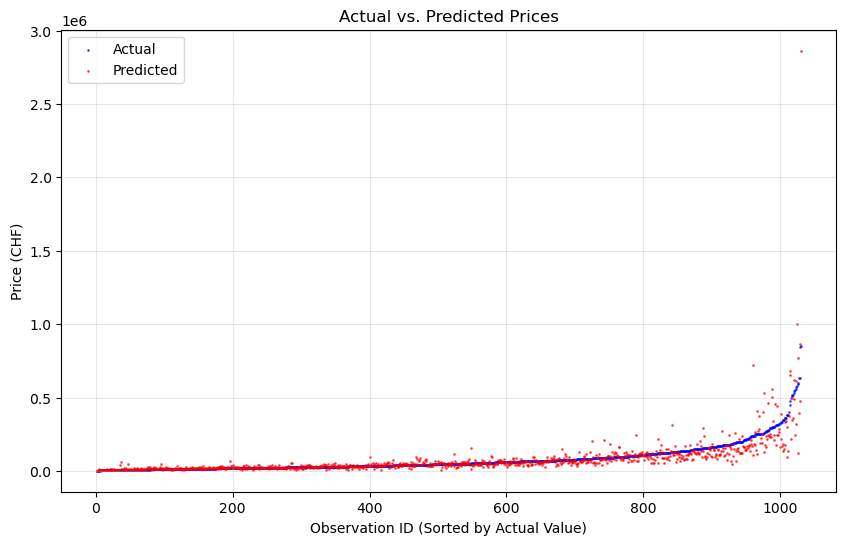

The average price prediction with our model is 80644.08161278463 higher than 


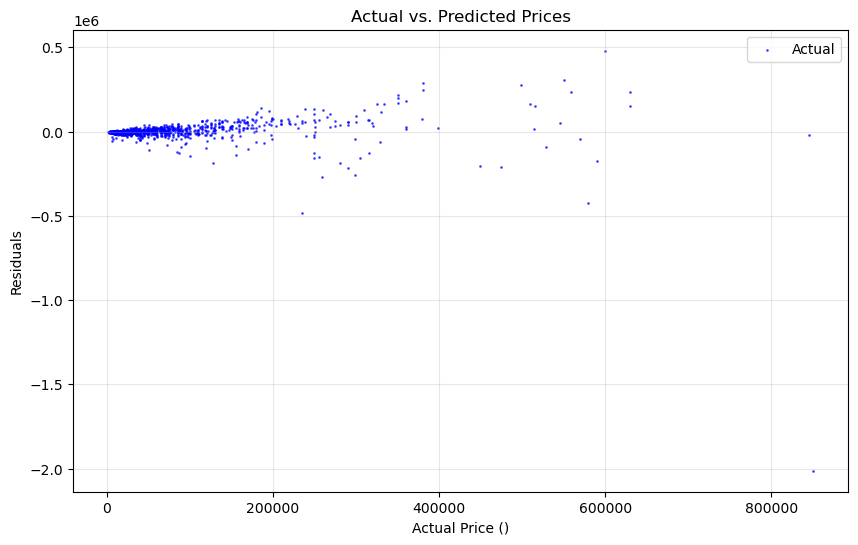

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print(df_clean.columns)
# Define variables to exclude
exclude_cols = ['URL', 'spec_listing_id', 'spec_width_m', 'spec_length_m', 'spec_price_chf', 'spec_motor']
df_fit = df_clean.drop(columns=exclude_cols)

# Convert all string columns to object type (for encoding)
df_fit = df_fit.astype({col: "object" for col in df_fit.select_dtypes(include="string").columns})

# One-hot encode categorical variables
df_fit = pd.get_dummies(df_fit, columns=df_fit.select_dtypes(include="object").columns, drop_first=True)

# Define Features (X) and Target (y)
X = df_fit.drop(columns=['log_spec_price_chf'])
y = df_fit['log_spec_price_chf']

#print(X.columns)

# Split data into train and test sets (80% train, 20% test)
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the model only on training data
lm = LinearRegression()
lm.fit(X, y)

# Predict on test data
y_pred = lm.predict(X)

# Convert back from log prices to original price scale
y_actual_exp = np.exp(df_fit['log_spec_price_chf'])
y_pred_exp = np.exp(y_pred)
# y_actual_exp = df_fit['log_spec_price_chf']
# y_pred_exp = y_pred
print(len(y_actual_exp))
print(len(y_pred_exp))

# Sort by actual values before assigning IDs
sorted_indices = np.argsort(y_actual_exp)

print(sorted_indices)

y_actual_sorted = y_actual_exp.iloc[sorted_indices].values
y_pred_sorted = y_pred_exp[sorted_indices]
print(len(y_actual_sorted))
print(len(y_pred_sorted))
# Assign an ID to each observation (sorted)
observation_ids = np.arange(1, len(y_actual_sorted) + 1)

# Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(observation_ids, y_actual_sorted, color="blue", label="Actual", alpha=0.6, s=1)
plt.scatter(observation_ids, y_pred_sorted, color="red", label="Predicted", alpha=0.6, s=1)
plt.xlabel("Observation ID (Sorted by Actual Value)")
plt.ylabel("Price (CHF)")
plt.title("Actual vs. Predicted Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Calculate and print mean deviation in price (converted back from log)
rmse = np.sqrt(mean_squared_error(y_actual_sorted, y_pred_sorted))
print(f'The average price prediction with our model is {rmse} higher than ')

# Plot residuals vs outcome
residuals = y_actual_sorted - y_pred_sorted

# Plot actual vs. predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_actual_sorted, residuals,color="blue", label="Actual", alpha=0.6, s=1)
plt.xlabel("Actual Price ()")
plt.ylabel("Residuals")
plt.title("Actual vs. Predicted Prices")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


